In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load the dataset
df = pd.read_csv('KaggleV2-May-2016.csv')

#Display basic information about the dataset
print("Shape", df.shape)

#Display the first few rows of the dataset
display(df.head())

df['No-show'].value_counts()


Shape (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


No-show
No     88208
Yes    22319
Name: count, dtype: int64

In [2]:
# Check data types and missing values
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
display(df.describe())



Data Types:
PatientId         float64
AppointmentID       int64
Gender                str
ScheduledDay          str
AppointmentDay        str
Age                 int64
Neighbourhood         str
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show               str
dtype: object

Missing Values:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Basic Statistics:


,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [3]:
# remove invalid age values (negative ages)
df = df[df['Age'] >= 0]

# Convert 'ScheduledDay' and 'AppointmentDay' to datetime
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

# Create a new feature: waiting days between booking and appointment
df['WaitingDays'] = (df['AppointmentDay'] - df['ScheduledDay']).dt.days

#Cap negative waiting days to 0
df['WaitingDays'] = df['WaitingDays'].clip(lower=0)

#Fix Handcap column - cap values at 1
df['Handcap'] = df['Handcap'].clip(upper=1)

# Encode target variable: Yes = 1 (no-show), No = 0 (showed up)
df['No-show'] = df['No-show'].map({'Yes': 1, 'No': 0})

#Encode Gender: F = 0, M = 1
df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})

print("\nData Types after preprocessing:")
print(df.dtypes)
display(df.head())




Data Types after preprocessing:
PatientId                     float64
AppointmentID                   int64
Gender                          int64
ScheduledDay      datetime64[us, UTC]
AppointmentDay    datetime64[us, UTC]
Age                             int64
Neighbourhood                     str
Scholarship                     int64
Hipertension                    int64
Diabetes                        int64
Alcoholism                      int64
Handcap                         int64
SMS_received                    int64
No-show                         int64
WaitingDays                     int64
dtype: object


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,WaitingDays
0,2.987250e+13,5642903,0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,0,0
1,5.589978e+14,5642503,1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,0,0
2,4.262962e+12,5642549,0,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,0,0
3,8.679512e+11,5642828,0,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,0
4,8.841186e+12,5642494,0,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,0,0


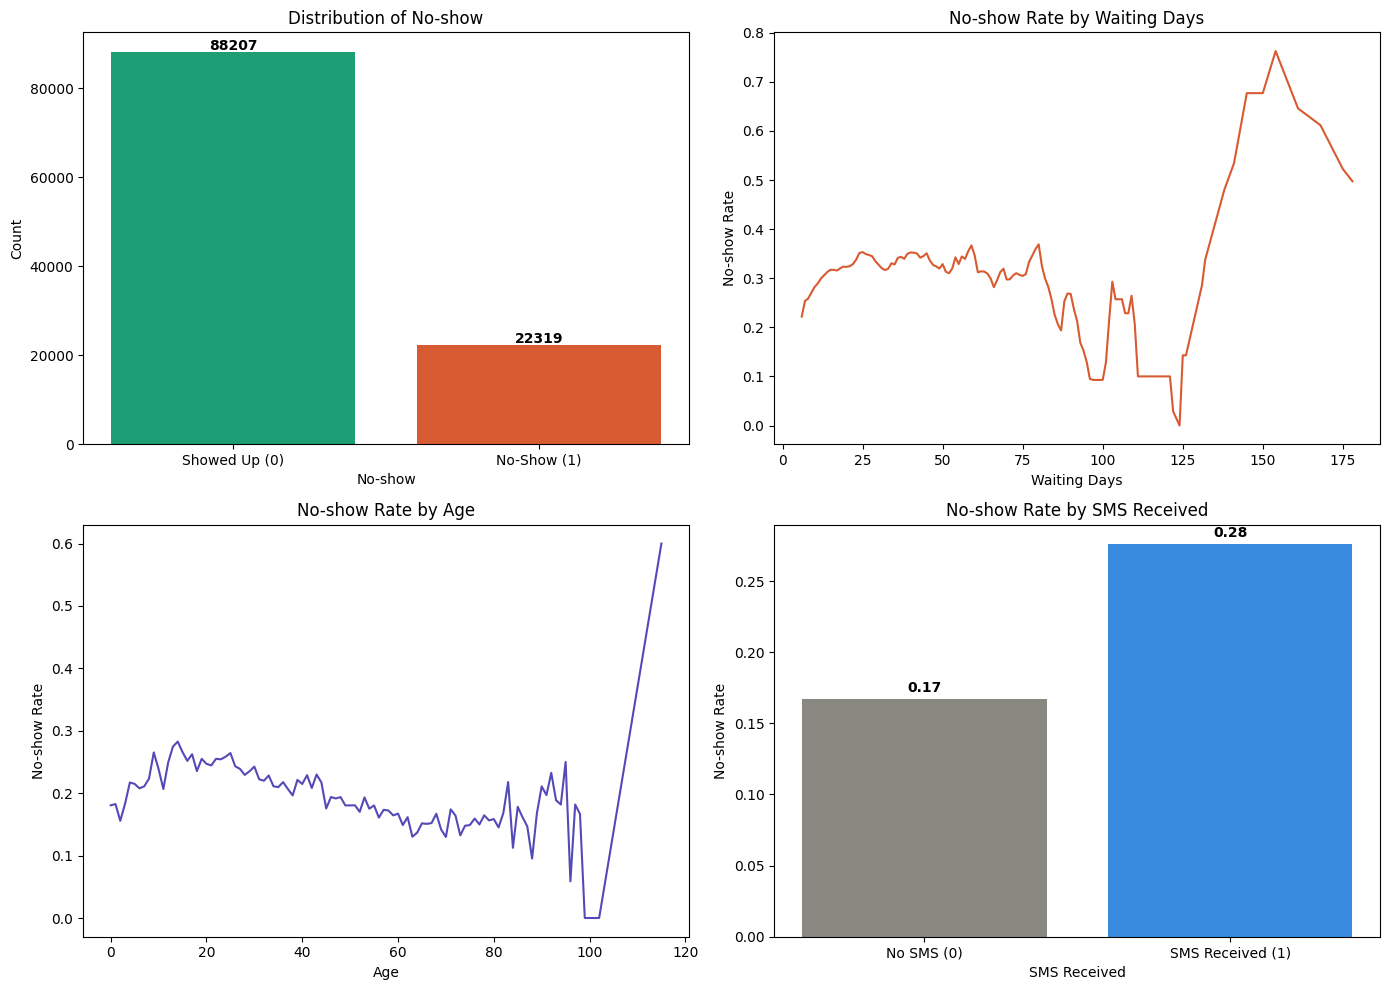

In [4]:
# Plot distribution of target variable
fig, axes =  plt.subplots(2, 2, figsize=(14, 10))

# Distribution of No-show
noshow_counts = df['No-show'].value_counts()
axes[0, 0].bar(['Showed Up (0)', 'No-Show (1)'], noshow_counts.values, color=['#1D9E75', '#D85A30'])
axes[0, 0].set_title('Distribution of No-show')
axes[0, 0].set_xlabel('No-show')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate(noshow_counts.values):
    axes[0, 0].text(i, v + 500, str(v), ha='center', fontweight='bold')

# 2. No - show by waiting days
df.groupby('WaitingDays')['No-show'].mean().rolling(7).mean().plot(ax=axes[0, 1], color='#D85A30')
axes[0, 1].set_title('No-show Rate by Waiting Days')
axes[0, 1].set_xlabel('Waiting Days')
axes[0, 1].set_ylabel('No-show Rate')

# 3. No-show by age 
df.groupby('Age')['No-show'].mean().plot(ax=axes[1, 0], color='#534AB7')
axes[1, 0].set_title('No-show Rate by Age')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('No-show Rate')

# 4. No-show by SMS received
sms_noshow = df.groupby('SMS_received')['No-show'].mean()
axes[1, 1].bar(['No SMS (0)', 'SMS Received (1)'], sms_noshow.values, color=['#888780', '#378ADD'])
axes[1, 1].set_title('No-show Rate by SMS Received')
axes[1, 1].set_xlabel('SMS Received')
axes[1, 1].set_ylabel('No-show Rate')
for i, v in enumerate(sms_noshow.values):
    axes[1, 1].text(i, v + 0.005, f"{v:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


# graph 1) The dataset is imbalanced (88,207 patient showing up and 22,319 not showing up.
#          This imbalance requires SMOTE to prevent model bias towards the majority class (showing up).
# graph 2) Patients with longer waiting times tend to have higher no-show rates.
#          The spike after 100 days may indicate data entry errors or outliers.
# graph 3) Younger patients show slightly higher no-show rates. The sharp increase beyond
#          100 years of age is unreliable due to very few data 
# graph 4) Patients who received SMS show a higher no-show rate compared to those who didn't
#          This is due to a confounding vaiable. SMS reminders are sent to patients with loger wating
#          days, which independently increase no-show risk.

In [5]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Define features and target
X = df[['Gender', 'Age', 'Scholarship', 'Hipertension', 'Diabetes', 
        'Alcoholism', 'Handcap', 'SMS_received', 'WaitingDays']]
y = df['No-show']

# Split into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Before SMOTE:")
print(f" Train - showed up: {(y_train == 0).sum()}, no-show: {(y_train == 1).sum()}")

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("\nAfter SMOTE:")
print(f" Train - showed up: {(y_train_smote == 0).sum()}, no-show: {(y_train_smote == 1).sum()}")
print(f"\nTest set (no SMOTE): {len(X_test)} rows")


Before SMOTE:
 Train - showed up: 70565, no-show: 17855

After SMOTE:
 Train - showed up: 70565, no-show: 70565

Test set (no SMOTE): 22106 rows


In [6]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Train XGBoost model

xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_smote, y_train_smote)

# Train Logistic Regression model (comparison)
logreg_model = LogisticRegression(max_iter=1000, random_state=42)
logreg_model.fit(X_train_smote, y_train_smote)

print("Both models trained")

# make predictions
xgb_pred  = xgb_model.predict(X_test)
logreg_pred = logreg_model.predict(X_test)

# Evaluate XGBoost
print("=" * 50)
print("XGBoost Results: ")
print("=" * 50)
print(classification_report(y_test, xgb_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, xgb_pred):.4f}")

# Evaluate Logistic Regression
print("=" * 50)
print("Logistic Regression Results: ")
print("=" * 50)
print(classification_report(y_test, logreg_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, logreg_pred):.4f}")

# 0 = attend 1 = no show
# support = actual number of data
# precision = all predicted no-show, how many were correct
# recall = all actual no-show, how many were correctly predicted
# f1-score = balance between precision and recall
# macro avg = average of precision, weighted avg = average weighted by support

Both models trained
XGBoost Results: 
              precision    recall  f1-score   support

           0       0.89      0.61      0.72     17642
           1       0.31      0.69      0.43      4464

    accuracy                           0.63     22106
   macro avg       0.60      0.65      0.58     22106
weighted avg       0.77      0.63      0.67     22106

ROC-AUC Score: 0.6533
Logistic Regression Results: 
              precision    recall  f1-score   support

           0       0.85      0.68      0.76     17642
           1       0.30      0.55      0.39      4464

    accuracy                           0.65     22106
   macro avg       0.58      0.61      0.57     22106
weighted avg       0.74      0.65      0.68     22106

ROC-AUC Score: 0.6115


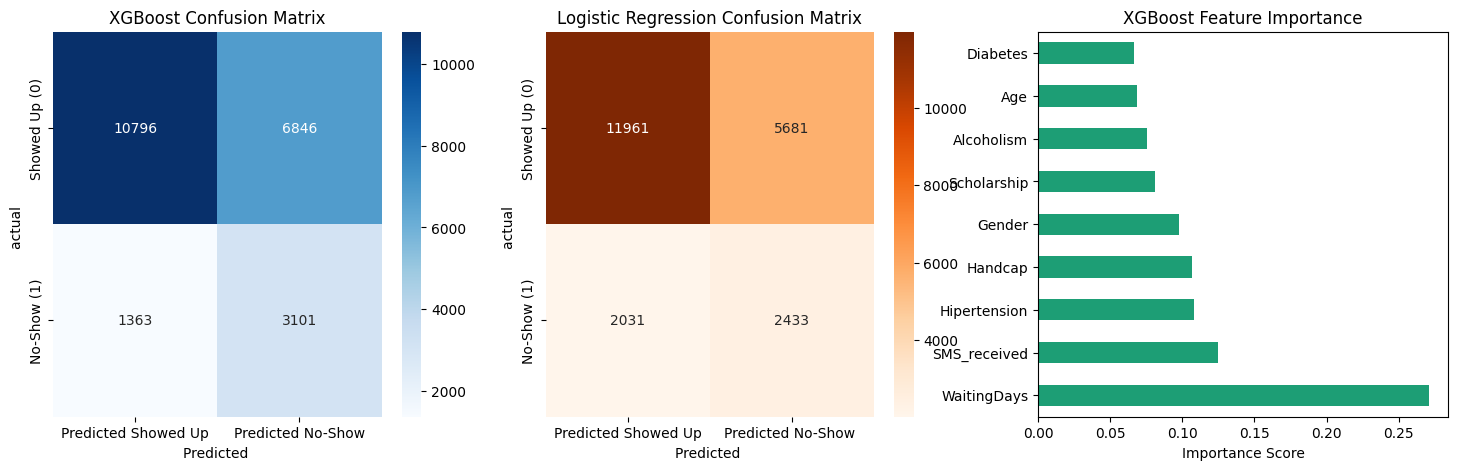

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1 confusion matrix for XGBoost
xgb_cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], yticklabels=['Showed Up (0)', 'No-Show (1)'], xticklabels=['Predicted Showed Up', 'Predicted No-Show'])
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_xlabel('Predicted ')
axes[0].set_ylabel('actual ')

#2 confusion matrix for Logistic Regression
logreg_cm = confusion_matrix(y_test, logreg_pred)
sns.heatmap(logreg_cm, annot=True, fmt='d', cmap='Oranges', ax=axes[1], yticklabels=['Showed Up (0)', 'No-Show (1)'], xticklabels=['Predicted Showed Up', 'Predicted No-Show '])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted ')
axes[1].set_ylabel('actual ')

#3 feature importance for XGBoost
xgb_importance = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
xgb_importance.plot(kind='barh', ax=axes[2], color='#1D9E75')
axes[2].set_title('XGBoost Feature Importance')
axes[2].set_xlabel('Importance Score')

plt.tight_layout
plt.show()

In [8]:
# comparision of XGBoost and Logistic Regression:
results = {
    'Model': ['XGBoost', 'Logistic Regression'],
    'Accuracy': [0.63, 0.65],
    'Precision (No-Show)': [0.31, 0.30],
    'Recall (No-Show)': [0.69, 0.55],
    'F1-Score (No-Show)': [0.43, 0.39],
    'ROC-AUC': [0.6533, 0.6115],
    'No-Shows Caught': [3101, 2433],
    'No-Shows Missed': [1363, 2031]
}

results_df = pd.DataFrame(results)
results_df.set_index('Model')
print("=" * 80)
print("comparision of XGBoost and Logistic Regression")
display(results_df)

print("\nHigher Recall 0.69 vs 0.55 means XGBoost is better at catching no-showsall")
print("Higher ROC AUC 0.65 vs 0.61 means XGBoost has better overall discrimination between show and no-show")
print("668 more no-shows caught by XGBoost (3101 vs 2433")


comparision of XGBoost and Logistic Regression


,Model,Accuracy,Precision (No-Show),Recall (No-Show),F1-Score (No-Show),ROC-AUC,No-Shows Caught,No-Shows Missed
0,XGBoost,0.63,0.31,0.69,0.43,0.6533,3101,1363
1,Logistic Regression,0.65,0.30,0.55,0.39,0.6115,2433,2031



Higher Recall 0.69 vs 0.55 means XGBoost is better at catching no-showsall
Higher ROC AUC 0.65 vs 0.61 means XGBoost has better overall discrimination between show and no-show
668 more no-shows caught by XGBoost (3101 vs 2433
